<a href="https://colab.research.google.com/github/asiddiqha/traffic-sign-recognition/blob/main/Traffic_Sign_Recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Traffic Sign Recognition

**Author:** Ayesha Siddiqha

## Project overview

Traffic sign recognition is an important part of driver-assistance systems. A vehicle needs to identify signs such as speed limits, stop signs, no-entry signs and road warnings correctly. A misclassification could lead to incorrect information being shown to the driver, so model accuracy is only one part of the problem.

In this project, I build an image-classification workflow that predicts the traffic sign shown in an image. I compare traditional machine-learning approaches with deep-learning models, then look beyond the overall score to understand where the models struggle.

### Project objectives

1. Prepare and explore the traffic-sign image dataset.
2. Train and compare traditional machine-learning and deep-learning models.
3. Evaluate performance using accuracy, macro F1, model size and prediction speed.
4. Examine errors and test how performance changes with blur, low light, glare, noise and partial obstruction.
5. Explore confidence-based prediction so uncertain results can be handled more cautiously.

The focus is on understanding model behaviour and identifying practical areas for improvement, rather than relying on accuracy alone.

**Dataset note:** The project brief contains a reference to predicting gender in its business-case section. That does not match the project title or the supplied traffic-sign data, so this notebook follows the traffic-sign recognition task supported by the dataset.


## 1. Environment and setup

The notebook uses TensorFlow/Keras to build the neural networks and scikit-learn for data splitting and evaluation metrics. The experiments were run in Google Colab with GPU acceleration enabled where available.

A fixed random seed is used to make the data split and model experiments more reproducible. Exact results can still vary across hardware and library versions.


In [ ]:
import os, glob, time, zipfile, hashlib, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

IMG_SIZE = 64          # I resize every image to 64x64
EPOCHS_CNN = 25        # early stopping will usually stop earlier
EPOCHS_TL = 15
EPOCHS_FT = 10
BATCH = 64
DATA_URL = "https://d3ilbtxij3aepc.cloudfront.net/projects/AI-Capstone-Projects/PRAICP-1002-TrafSignDetc.zip"
DATA_DIR = "traffic_data"
PRETRAINED = "imagenet"

print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Downloading and extracting the dataset

The dataset is provided as a ZIP archive. This step downloads the archive and extracts its contents so the image files and label information can be loaded in the following sections.

If the download URL is unavailable, the archive can be downloaded manually and uploaded to the Colab session before running the extraction cell.


In [ ]:
zip_name = "PRAICP-1002-TrafSignDetc.zip"
if not os.path.exists(DATA_DIR):
    if not os.path.exists(zip_name):
        os.system(f"wget -q -O {zip_name} {DATA_URL}")
    with zipfile.ZipFile(zip_name) as z:
        z.extractall(DATA_DIR)
print("Unzipped into:", DATA_DIR)

Unzipped into: traffic_data


## 3. Loading images and assigning labels

The dataset follows the German Traffic Sign Recognition Benchmark (GTSRB) structure:

- `train/<class number>/` contains training images grouped by class. The folder name provides the label.
- `test/` contains test images in a single folder. Their labels are stored separately in `Test.csv`, under `ClassId`.
- `meta/` contains clean reference drawings of the signs. These are not road photographs, so they are excluded from model training and evaluation.

An issue in the initial data-loading approach was that it treated every image's parent folder as its label. For test images, this assigned the same label (`test`) to every image; the reference drawings could also be treated as a separate `meta` class. That creates incorrect training labels and makes the evaluation unreliable.

The loader now reads test labels from `Test.csv` and excludes the reference drawings. The labelled images are then combined so a stratified train/validation/test split can be created consistently.


In [ ]:
EXTS = (".png", ".jpg", ".jpeg", ".ppm", ".bmp")

# Labels for the test images come from Test.csv (file name -> ClassId)
test_labels = {}
for csv_path in glob.glob(f"{DATA_DIR}/**/*.csv", recursive=True):
    if os.path.basename(csv_path).lower() == "test.csv":
        t = pd.read_csv(csv_path)
        test_labels.update({os.path.basename(p): str(c) for p, c in zip(t["Path"], t["ClassId"])})
print("Test labels found in Test.csv:", len(test_labels))

rows, skipped = [], {"meta (reference drawings)": 0, "test image without a label": 0, "other": 0}
for root, _, files in os.walk(DATA_DIR):
    if "__MACOSX" in root:
        continue
    folder = os.path.basename(root)
    for f in files:
        if not f.lower().endswith(EXTS):
            continue
        path = os.path.join(root, f)
        if folder.isdigit():                       # train/<class>/image.png
            rows.append({"path": path, "label": folder, "source": "train"})
        elif folder.lower() == "test":             # test/image.png, label from Test.csv
            if f in test_labels:
                rows.append({"path": path, "label": test_labels[f], "source": "test"})
            else:
                skipped["test image without a label"] += 1
        elif folder.lower() == "meta":
            skipped["meta (reference drawings)"] += 1
        else:
            skipped["other"] += 1

df = pd.DataFrame(rows)
print("Labelled images found:", len(df), "| from train:", (df["source"] == "train").sum(), "| from test:", (df["source"] == "test").sum())
print("Classes found:", df["label"].nunique())
print("Skipped:", skipped)
df.head()

Test labels found in Test.csv: 12630
Labelled images found: 103678 | from train: 78418 | from test: 25260
Classes found: 43
Skipped: {'meta (reference drawings)': 86, 'test image without a label': 0, 'other': 0}


,path,label,source
0,traffic_data/Test/08679.png,2,test
1,traffic_data/Test/10477.png,18,test
2,traffic_data/Test/02334.png,17,test
3,traffic_data/Test/04454.png,18,test
4,traffic_data/Test/00949.png,22,test


When the class folders are numbered from 0 to 42, they represent the 43 GTSRB traffic-sign classes. I map those numeric IDs to readable sign names so that the charts, classification reports and error analysis are easier to interpret.


In [ ]:
GTSRB_NAMES = ["Speed limit 20","Speed limit 30","Speed limit 50","Speed limit 60","Speed limit 70",
 "Speed limit 80","End of speed limit 80","Speed limit 100","Speed limit 120","No passing",
 "No passing for trucks","Right-of-way at next intersection","Priority road","Yield","Stop",
 "No vehicles","Trucks prohibited","No entry","General caution","Dangerous curve left",
 "Dangerous curve right","Double curve","Bumpy road","Slippery road","Road narrows on right",
 "Road work","Traffic signals","Pedestrians","Children crossing","Bicycles crossing",
 "Beware of ice/snow","Wild animals crossing","End of all limits","Turn right ahead","Turn left ahead",
 "Ahead only","Go straight or right","Go straight or left","Keep right","Keep left",
 "Roundabout","End of no passing","End of no passing for trucks"]

labels = sorted(df["label"].unique())
if all(l.isdigit() and int(l) < 43 for l in labels):
    df["label"] = df["label"].astype(int).map(lambda i: f"{i:02d} {GTSRB_NAMES[i]}")
    print("Mapped numeric folders to sign names.")
else:
    print("Keeping folder names as labels:", labels[:10], "...")

Mapped numeric folders to sign names.


## 4. Data quality checks

Before training, I check the image files for issues that could affect the results:

1. **Unreadable files:** images that cannot be opened are removed.
2. **Exact duplicates:** duplicate images are identified so that the same image does not appear in both training and evaluation data.
3. **Very small images:** images smaller than 10 pixels in either dimension are removed because they contain too little visual information.

I also capture each image's dimensions and brightness. These measurements help describe the dataset and inform the preprocessing and robustness experiments later in the notebook.


In [ ]:
info = []
for p in df["path"]:
    try:
        with Image.open(p) as im:
            im = im.convert("RGB")
            w, h = im.size
            arr = np.asarray(im.resize((32, 32)))
            info.append((w, h, arr.mean(), hashlib.md5(open(p, "rb").read()).hexdigest(), True))
    except Exception:
        info.append((0, 0, np.nan, None, False))
df[["width", "height", "brightness", "md5", "readable"]] = pd.DataFrame(info, index=df.index)

before = len(df)
n_broken = (~df["readable"]).sum()
df = df[df["readable"]]
n_dupes = df.duplicated("md5").sum()
df = df.drop_duplicates("md5")
n_tiny = ((df["width"] < 10) | (df["height"] < 10)).sum()
df = df[(df["width"] >= 10) & (df["height"] >= 10)].reset_index(drop=True)

print(f"Started with {before} images")
print(f"Dropped {n_broken} broken, {n_dupes} duplicates, {n_tiny} tiny")
print(f"Clean dataset: {len(df)} images, {df['label'].nunique()} classes")

Started with 103678 images
Dropped 0 broken, 51847 duplicates, 0 tiny
Clean dataset: 51831 images, 43 classes


## 5. Exploratory data analysis

### 5.1 Image count by traffic-sign class

The number of examples available for each class affects how often the model sees that sign during training. I start by checking the class distribution to identify any imbalance.


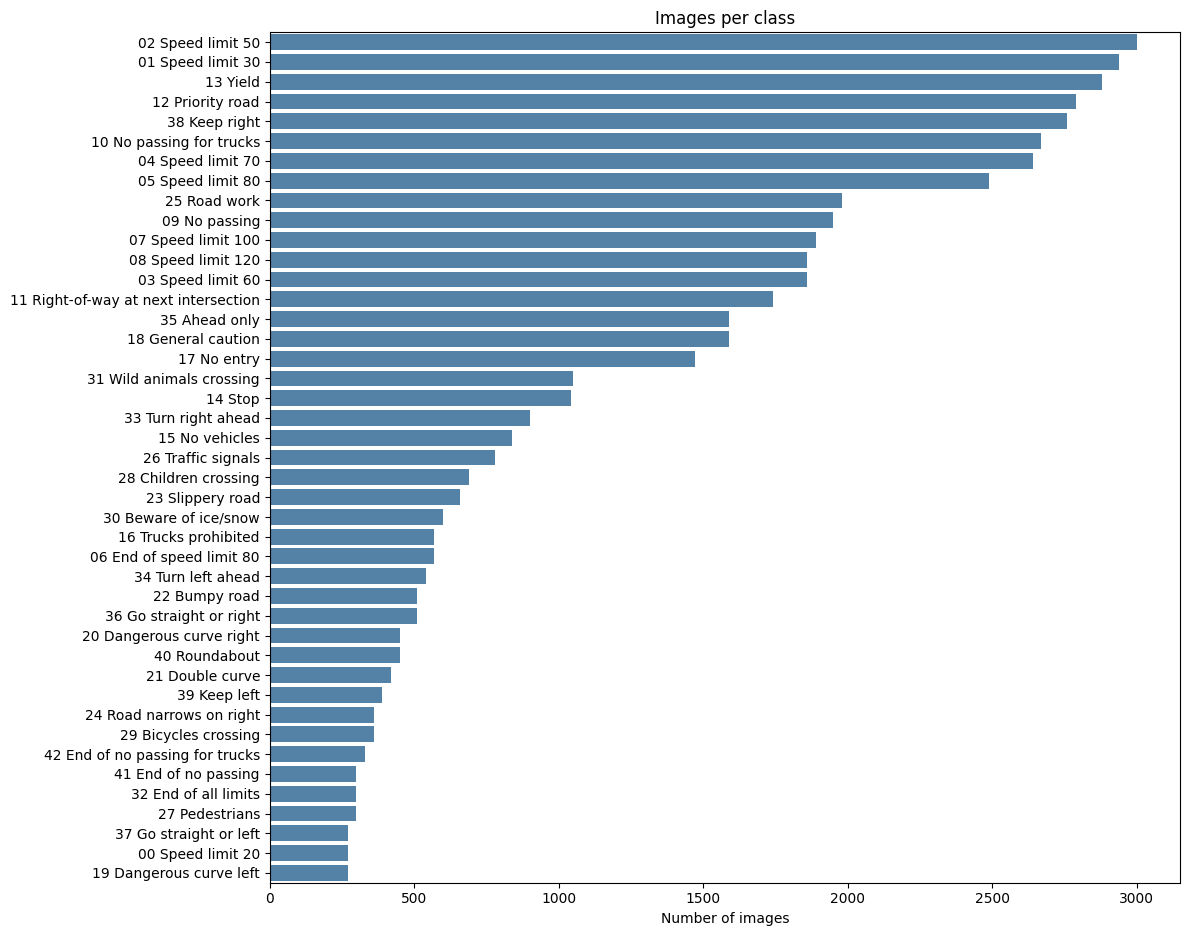

Smallest class: 270 images | Largest class: 3000 images | Ratio: 11.1x


In [ ]:
counts = df["label"].value_counts()
plt.figure(figsize=(12, max(4, len(counts) * 0.22)))
sns.barplot(x=counts.values, y=counts.index, color="steelblue")
plt.title("Images per class"); plt.xlabel("Number of images"); plt.ylabel("")
plt.tight_layout(); plt.show()
print(f"Smallest class: {counts.min()} images | Largest class: {counts.max()} images | Ratio: {counts.max()/counts.min():.1f}x")

**Interpretation:** The class distribution shows whether some signs have substantially fewer examples than others. Where the data is imbalanced, I use class weights during training so that less frequent classes receive more attention. I also report macro F1, which gives each class equal weight in the final average.


### 5.2 Sample images

I inspect a selection of images from different classes to get a sense of the visual differences between signs and the variation in the photographs.


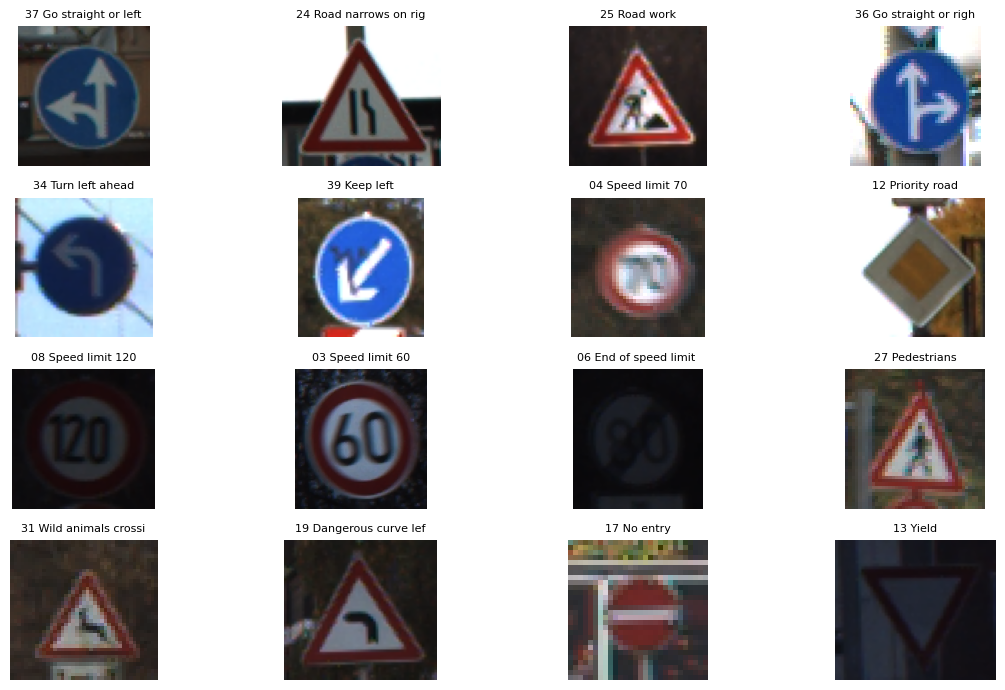

In [ ]:
sample = df.groupby("label").sample(1, random_state=SEED).sample(min(16, df["label"].nunique()), random_state=SEED)
plt.figure(figsize=(12, 7))
for i, (_, r) in enumerate(sample.iterrows()):
    plt.subplot(4, 4, i + 1)
    plt.imshow(Image.open(r["path"]).convert("RGB"))
    plt.title(r["label"][:22], fontsize=8); plt.axis("off")
plt.tight_layout(); plt.show()

### 5.3 Image dimensions and brightness

The source images do not all have the same dimensions, so they need to be resized before they can be passed to a model in batches. I also examine brightness to understand how much variation there is between well-lit and darker images.


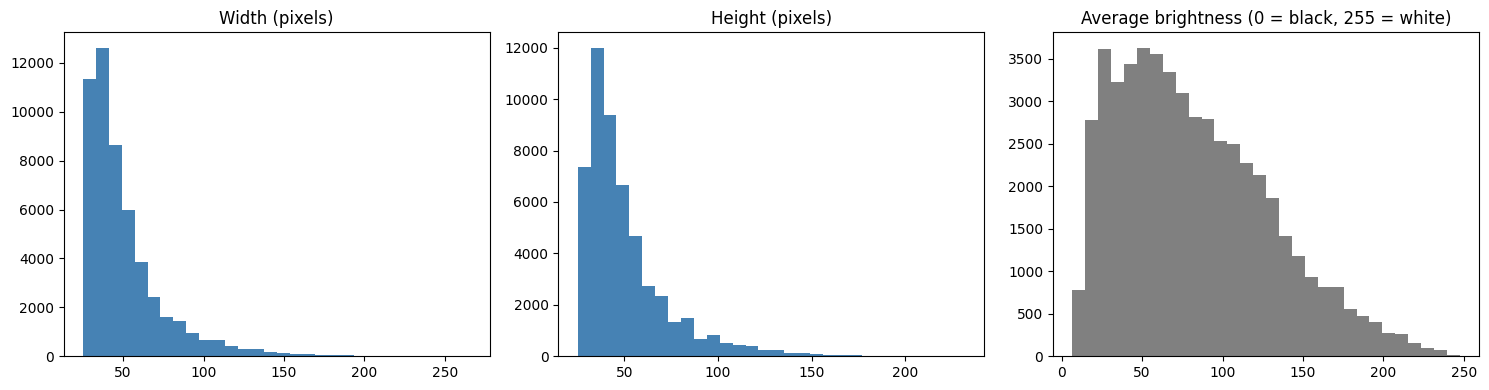

         width   height  brightness
count  51831.0  51831.0     51831.0
mean      50.8     50.3        82.6
std       24.5     23.3        47.2
min       25.0     25.0         6.6
25%       34.0     35.0        44.8
50%       43.0     43.0        74.7
75%       58.0     58.0       113.7
max      266.0    232.0       247.5
Dark images (brightness < 50): 29.7%


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(df["width"], bins=30, color="steelblue"); ax[0].set_title("Width (pixels)")
ax[1].hist(df["height"], bins=30, color="steelblue"); ax[1].set_title("Height (pixels)")
ax[2].hist(df["brightness"], bins=30, color="gray"); ax[2].set_title("Average brightness (0 = black, 255 = white)")
plt.tight_layout(); plt.show()
print(df[["width", "height", "brightness"]].describe().round(1))
print(f"Dark images (brightness < 50): {(df['brightness'] < 50).mean():.1%}")

**Interpretation:** Many images are small, which makes 64 × 64 a practical input size for the initial experiments: it retains the main sign shape while keeping training manageable. The brightness distribution also includes darker images, making low-light performance worth checking separately.


## 6. Preprocessing and data splitting

The images are prepared consistently before model training:

- **Resize:** each image is converted to 64 × 64 pixels with three colour channels (RGB).
- **Pixel values:** values remain in the 0–255 range at this stage. Each model applies its own rescaling layer so that the input pipeline remains consistent.
- **Data split:** the labelled data is divided into training, validation and test sets using a 70 / 15 / 15 split. Stratification preserves the class proportions across the three sets.

The training set is used to fit the models, the validation set is used for model selection, and the test set is held back for the final evaluation.


In [ ]:
def load_images(paths):
    return np.stack([np.asarray(Image.open(p).convert("RGB").resize((IMG_SIZE, IMG_SIZE))) for p in paths]).astype("uint8")

classes = sorted(df["label"].unique())
class_to_id = {c: i for i, c in enumerate(classes)}
y_all = df["label"].map(class_to_id).values
X_all = load_images(df["path"])

X_train, X_tmp, y_train, y_tmp = train_test_split(X_all, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
NUM_CLASSES = len(classes)

cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weights = dict(enumerate(cw))
print(f"Train {X_train.shape} | Val {X_val.shape} | Test {X_test.shape} | Classes {NUM_CLASSES}")

Train (36281, 64, 64, 3) | Val (7775, 64, 64, 3) | Test (7775, 64, 64, 3) | Classes 43


### Data augmentation

I apply small changes to training images during training, including rotations, zoom, shifts and contrast adjustments. The aim is to expose the model to reasonable image variation and reduce its dependence on the exact appearance of the training examples.

**Why I do not use horizontal flips:** a horizontal flip can change the meaning of a sign. For example, a left-turn sign could become a right-turn sign while keeping the original label. That would introduce incorrect training examples, so horizontal flipping is excluded.


In [ ]:
augment = keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.2),
], name="augment")

## 7. Traditional machine-learning baselines

Before training neural networks, I establish two traditional machine-learning baselines. These provide a useful point of comparison and help show whether the additional complexity of deep learning improves the results.

Traditional classifiers need numerical features rather than raw image files, so I test two feature representations:

1. **Random Forest on raw pixels:** each image is resized to 32 × 32 and its pixel values are used as features. This is a straightforward baseline, although it does not explicitly represent the spatial relationships between neighbouring pixels.
2. **HOG features with a Linear SVM:** Histogram of Oriented Gradients (HOG) describes edge directions in local image regions. Since traffic signs contain distinctive outlines and symbols, these shape-related features provide a useful representation for classification.

The two approaches establish baseline performance for the CNN and MobileNetV2 models that follow.


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from skimage.feature import hog
from skimage.transform import resize

def pixel_features(X):
    # shrink to 32x32 and flatten: 32*32*3 = 3072 numbers per image
    return np.stack([resize(x, (32, 32), anti_aliasing=True).ravel() for x in X])

def hog_features(X):
    # edge directions in 8x8 pixel patches, on the grayscale image
    return np.stack([hog(resize(x.mean(axis=2), (48, 48), anti_aliasing=True), orientations=9,
                         pixels_per_cell=(8, 8), cells_per_block=(2, 2)) for x in X])

t0 = time.time()
Xtr_pix, Xval_pix = pixel_features(X_train), pixel_features(X_val)
rf = RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=SEED)
rf.fit(Xtr_pix, y_train)
time_rf = time.time() - t0

t0 = time.time()
Xtr_hog, Xval_hog = hog_features(X_train), hog_features(X_val)
svm = make_pipeline(StandardScaler(), LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=SEED))
svm.fit(Xtr_hog, y_train)
time_svm = time.time() - t0

print(f"Pixel features: {Xtr_pix.shape[1]} per image | HOG features: {Xtr_hog.shape[1]} per image")
for name, m, Xv in [("Random Forest (pixels)", rf, Xval_pix), ("HOG + Linear SVM", svm, Xval_hog)]:
    p = m.predict(Xv)
    print(f"{name}: val accuracy {accuracy_score(y_val, p):.4f} | val macro F1 {f1_score(y_val, p, average='macro'):.4f}")

Pixel features: 3072 per image | HOG features: 900 per image
Random Forest (pixels): val accuracy 0.9826 | val macro F1 0.9829
HOG + Linear SVM: val accuracy 0.9534 | val macro F1 0.9600


**What this comparison helps establish:** HOG features can represent sign outlines and symbols more directly than a flat list of pixel values, so HOG + SVM is a useful baseline to compare against the Random Forest. The measured results below determine how both baselines perform on this dataset.


## 8. Model 1 — Convolutional Neural Network (CNN)

I first train a small CNN from scratch. A convolutional network learns image features directly from the pixels instead of relying on manually designed features.

In general, early layers can learn simple visual patterns such as edges and colour changes. Deeper layers combine these patterns into more complex shapes and sign symbols. This makes a CNN a natural next step after the traditional feature-based baselines.


In [ ]:
def build_cnn():
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augment(inp)
    x = layers.Rescaling(1 / 255.0)(x)
    for f in [32, 64, 128]:
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(0.25)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name="simple_cnn")

def make_callbacks():
    # A fresh set for every training run. Reusing one set made the second model compare itself
    # with the first model's best score, so it stopped too early and kept its worst weights.
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)]

cnn = build_cnn()
cnn.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t0 = time.time()
hist_cnn = cnn.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=EPOCHS_CNN, batch_size=BATCH,
                   class_weight=class_weights, callbacks=make_callbacks(), verbose=2)
time_cnn = time.time() - t0
print(f"Training time: {time_cnn/60:.1f} min | Parameters: {cnn.count_params():,}")

Epoch 1/25
567/567 - 37s - 65ms/step - accuracy: 0.1570 - loss: 2.8841 - val_accuracy: 0.3313 - val_loss: 2.1489 - learning_rate: 0.0010
Epoch 2/25
567/567 - 25s - 43ms/step - accuracy: 0.4900 - loss: 1.4465 - val_accuracy: 0.8269 - val_loss: 0.5856 - learning_rate: 0.0010
Epoch 3/25
567/567 - 24s - 43ms/step - accuracy: 0.7882 - loss: 0.5558 - val_accuracy: 0.8931 - val_loss: 0.3363 - learning_rate: 0.0010
Epoch 4/25
567/567 - 24s - 43ms/step - accuracy: 0.8884 - loss: 0.2830 - val_accuracy: 0.9493 - val_loss: 0.1932 - learning_rate: 0.0010
Epoch 5/25
567/567 - 24s - 43ms/step - accuracy: 0.9300 - loss: 0.1904 - val_accuracy: 0.9762 - val_loss: 0.0762 - learning_rate: 0.0010
Epoch 6/25
567/567 - 24s - 43ms/step - accuracy: 0.9488 - loss: 0.1357 - val_accuracy: 0.9856 - val_loss: 0.0549 - learning_rate: 0.0010
Epoch 7/25
567/567 - 24s - 43ms/step - accuracy: 0.9534 - loss: 0.1292 - val_accuracy: 0.9914 - val_loss: 0.0274 - learning_rate: 0.0010
Epoch 8/25
567/567 - 24s - 42ms/step - ac

## 9. Model 2 — MobileNetV2 transfer learning

For the second deep-learning approach, I use MobileNetV2 with pretrained ImageNet weights. Rather than learning every visual feature from the beginning, the model starts with features learned from a large general-image dataset and is adapted to the traffic-sign classes.

MobileNetV2 is a relatively lightweight architecture, making it a useful candidate to investigate for applications where model size and inference speed matter.

Training is carried out in two stages:

1. **Feature extraction:** the pretrained base is frozen while the new classification layers are trained for the traffic-sign classes.
2. **Fine-tuning:** selected layers near the end of the pretrained network are unfrozen and trained with a low learning rate so the features can adapt to this dataset.

The model uses a 96 × 96 input internally, while the shared preprocessing pipeline initially produces 64 × 64 images.


In [ ]:
def build_mobilenet():
    base = keras.applications.MobileNetV2(input_shape=(96, 96, 3), include_top=False, weights=PRETRAINED)
    base.trainable = False
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augment(inp)
    x = layers.Resizing(96, 96)(x)
    x = layers.Rescaling(1 / 127.5, offset=-1)(x)   # MobileNetV2 expects pixels in [-1, 1]
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name="mobilenetv2_tl"), base

tl, base = build_mobilenet()
tl.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t0 = time.time()
hist_tl = tl.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=EPOCHS_TL, batch_size=BATCH,
                 class_weight=class_weights, callbacks=make_callbacks(), verbose=2)

# Stage 2: fine-tune the last 30 layers
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
tl.compile(optimizer=keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist_ft = tl.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=EPOCHS_FT, batch_size=BATCH,
                 class_weight=class_weights, callbacks=make_callbacks(), verbose=2)
time_tl = time.time() - t0
print(f"Training time: {time_tl/60:.1f} min | Parameters: {tl.count_params():,}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
567/567 - 23s - 41ms/step - accuracy: 0.5044 - loss: 1.6651 - val_accuracy: 0.7010 - val_loss: 0.9182 - learning_rate: 0.0010
Epoch 2/15
567/567 - 16s - 28ms/step - accuracy: 0.6780 - loss: 0.9133 - val_accuracy: 0.7452 - val_loss: 0.7654 - learning_rate: 0.0010
Epoch 3/15
567/567 - 21s - 36ms/step - accuracy: 0.7239 - loss: 0.7547 - val_accuracy: 0.7628 - val_loss: 0.6989 - learning_rate: 0.0010
Epoch 4/15
567/567 - 16s - 29ms/step - accuracy: 0.7431 - loss: 0.6862 - val_accuracy: 0.7924 - val_loss: 0.6121 - learning_rate: 0.0010
Epoch 5/15
567/567 - 16s - 28ms/step - accuracy: 0.7514 - loss: 0.6452 - val_accuracy: 0.7995 - val_loss: 0.5834 - learning_rate: 0.0010
Epoch 6/15
567/567 - 16s - 28ms/step - accuracy: 0.7586 - loss: 0.6097 - val_accuracy: 0.7960 - val_loss: 0.6013 - learning_rate: 0.0010
Epoch 7/15
567/567 - 19s - 33ms/step - accuracy: 0.7628 - loss: 0.5922 - val_accuracy: 0.8112 - val_loss: 0.5527 - learning_rate:

### Training curves

I compare training and validation loss across epochs to look for signs of overfitting. Ideally, both losses improve together. If training loss continues to decrease while validation loss starts increasing, the model may be fitting the training examples too closely rather than generalising to unseen images.


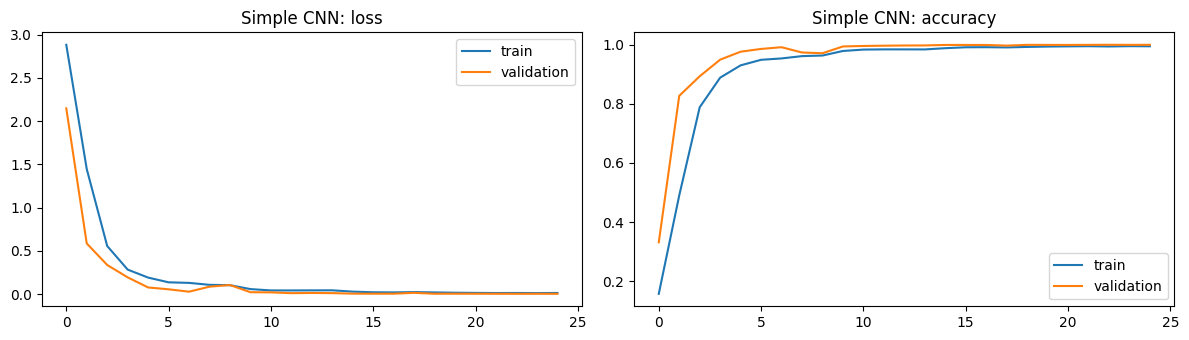

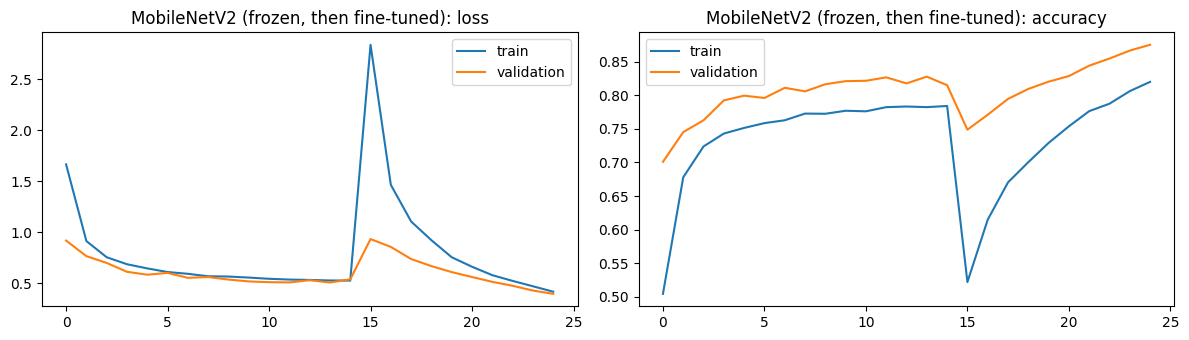

In [ ]:
def plot_hist(histories, title):
    loss = sum([h.history["loss"] for h in histories], [])
    vloss = sum([h.history["val_loss"] for h in histories], [])
    acc = sum([h.history["accuracy"] for h in histories], [])
    vacc = sum([h.history["val_accuracy"] for h in histories], [])
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    ax[0].plot(loss, label="train"); ax[0].plot(vloss, label="validation"); ax[0].set_title(f"{title}: loss"); ax[0].legend()
    ax[1].plot(acc, label="train"); ax[1].plot(vacc, label="validation"); ax[1].set_title(f"{title}: accuracy"); ax[1].legend()
    plt.tight_layout(); plt.show()

plot_hist([hist_cnn], "Simple CNN")
plot_hist([hist_tl, hist_ft], "MobileNetV2 (frozen, then fine-tuned)")

## 10. Comparing the four models

I compare all four approaches on the validation set:

- **Accuracy:** the proportion of images classified correctly.
- **Macro F1:** the average F1 score across classes, giving each traffic-sign class equal importance.
- **Inference time:** the time taken to predict one image, which matters for applications that need timely predictions.
- **Model size:** the number of parameters, as a rough indicator of the model's computational footprint.

Using several measures gives a more balanced view than choosing a model from accuracy alone.


In [ ]:
def evaluate(model, X, y):
    t0 = time.time()
    probs = model.predict(X, batch_size=256, verbose=0)
    ms = (time.time() - t0) / len(X) * 1000
    pred = probs.argmax(1)
    return probs, pred, accuracy_score(y, pred), f1_score(y, pred, average="macro"), ms

results = []
for name, m, Xv, t in [("Random Forest (pixels)", rf, X_val, time_rf), ("HOG + Linear SVM", svm, X_val, time_svm)]:
    t0 = time.time()
    feats = pixel_features(Xv) if m is rf else hog_features(Xv)   # feature extraction counts towards speed
    p = m.predict(feats)
    ms = (time.time() - t0) / len(Xv) * 1000
    results.append({"Model": name, "Val accuracy": round(accuracy_score(y_val, p), 4),
                    "Val macro F1": round(f1_score(y_val, p, average="macro"), 4), "ms per image": round(ms, 2),
                    "Parameters": "n/a (classic ML)", "Train time (min)": round(t / 60, 1)})
for name, m, t in [("Simple CNN", cnn, time_cnn), ("MobileNetV2 transfer learning", tl, time_tl)]:
    _, _, acc, f1, ms = evaluate(m, X_val, y_val)
    results.append({"Model": name, "Val accuracy": round(acc, 4), "Val macro F1": round(f1, 4),
                    "ms per image": round(ms, 2), "Parameters": f"{m.count_params():,}", "Train time (min)": round(t / 60, 1)})
comparison = pd.DataFrame(results)
comparison

,Model,Val accuracy,Val macro F1,ms per image,Parameters,Train time (min)
0,Random Forest (pixels),0.9826,0.9829,0.86,n/a (classic ML),12.7
1,HOG + Linear SVM,0.9534,0.9600,1.26,n/a (classic ML),6.4
2,Simple CNN,0.9995,0.9996,0.37,"309,963",10.3
3,MobileNetV2 transfer learning,0.8752,0.8867,0.62,"2,313,067",8.8


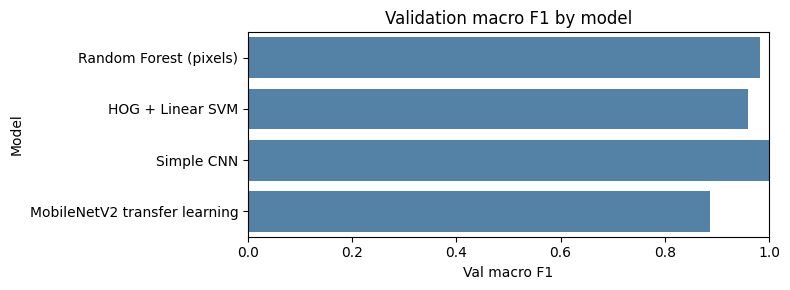

Best deep learning model: Simple CNN
Gain over the best classic ML baseline: +1.7 macro F1 points


In [ ]:
plt.figure(figsize=(8, 3))
sns.barplot(data=comparison, x="Val macro F1", y="Model", color="steelblue")
plt.xlim(0, 1); plt.title("Validation macro F1 by model"); plt.tight_layout(); plt.show()

deep = comparison[comparison["Model"].isin(["Simple CNN", "MobileNetV2 transfer learning"])]
best_name = deep.sort_values("Val macro F1", ascending=False).iloc[0]["Model"]
best = cnn if best_name == "Simple CNN" else tl
gain = deep["Val macro F1"].max() - comparison.loc[~comparison.index.isin(deep.index), "Val macro F1"].max()
print("Best deep learning model:", best_name)
print(f"Gain over the best classic ML baseline: {gain*100:+.1f} macro F1 points")

**Model selection:** I use validation macro F1 as the main comparison metric for the deep-learning models. If their scores are close, model size and inference speed become useful deciding factors.

I carry the selected deep-learning model into the remaining evaluation because it learns features directly from images and provides class probabilities for the confidence analysis. The baseline comparison above shows the measured difference between the traditional and deep-learning approaches.


## 11. Final evaluation on the test set

After selecting the model using validation results, I evaluate it on the held-out test set. These images were not used for training or model selection, so this gives a more independent estimate of performance on unseen examples.


In [ ]:
test_probs, test_pred, test_acc, test_f1, _ = evaluate(best, X_test, y_test)
print(f"{best_name} | Test accuracy: {test_acc:.4f} | Test macro F1: {test_f1:.4f}\n")
report = classification_report(y_test, test_pred, target_names=classes, output_dict=True, zero_division=0)
print(classification_report(y_test, test_pred, target_names=classes, zero_division=0))

Simple CNN | Test accuracy: 0.9994 | Test macro F1: 0.9997

                                      precision    recall  f1-score   support

                   00 Speed limit 20       1.00      1.00      1.00        40
                   01 Speed limit 30       1.00      1.00      1.00       441
                   02 Speed limit 50       1.00      1.00      1.00       450
                   03 Speed limit 60       1.00      1.00      1.00       279
                   04 Speed limit 70       1.00      1.00      1.00       396
                   05 Speed limit 80       1.00      1.00      1.00       373
            06 End of speed limit 80       1.00      1.00      1.00        86
                  07 Speed limit 100       1.00      1.00      1.00       283
                  08 Speed limit 120       1.00      1.00      1.00       279
                       09 No passing       1.00      1.00      1.00       292
            10 No passing for trucks       1.00      1.00      1.00       400
11 

### 11.1 Classes with the lowest F1 scores

I identify the classes with the lowest F1 scores to see which traffic signs are most difficult for the selected model. These classes are useful candidates for collecting additional training examples or reviewing image quality.


In [ ]:
per_class = pd.DataFrame(report).T.loc[classes, ["precision", "recall", "f1-score", "support"]]
per_class.sort_values("f1-score").head(8).round(3)

,precision,recall,f1-score,support
25 Road work,1.000,0.993,0.997,297.0
05 Speed limit 80,0.997,0.997,0.997,373.0
11 Right-of-way at next intersection,0.996,1.000,0.998,261.0
03 Speed limit 60,1.000,0.996,0.998,279.0
04 Speed limit 70,1.000,0.997,0.999,396.0
12 Priority road,0.998,1.000,0.999,419.0
01 Speed limit 30,0.998,1.000,0.999,441.0
02 Speed limit 50,0.998,1.000,0.999,450.0


### 11.2 Confusion matrix

The confusion matrix compares the true class with the predicted class. Rows represent the actual labels and columns represent the model predictions. Correct predictions appear along the diagonal; values outside the diagonal show which classes the model confuses with one another.


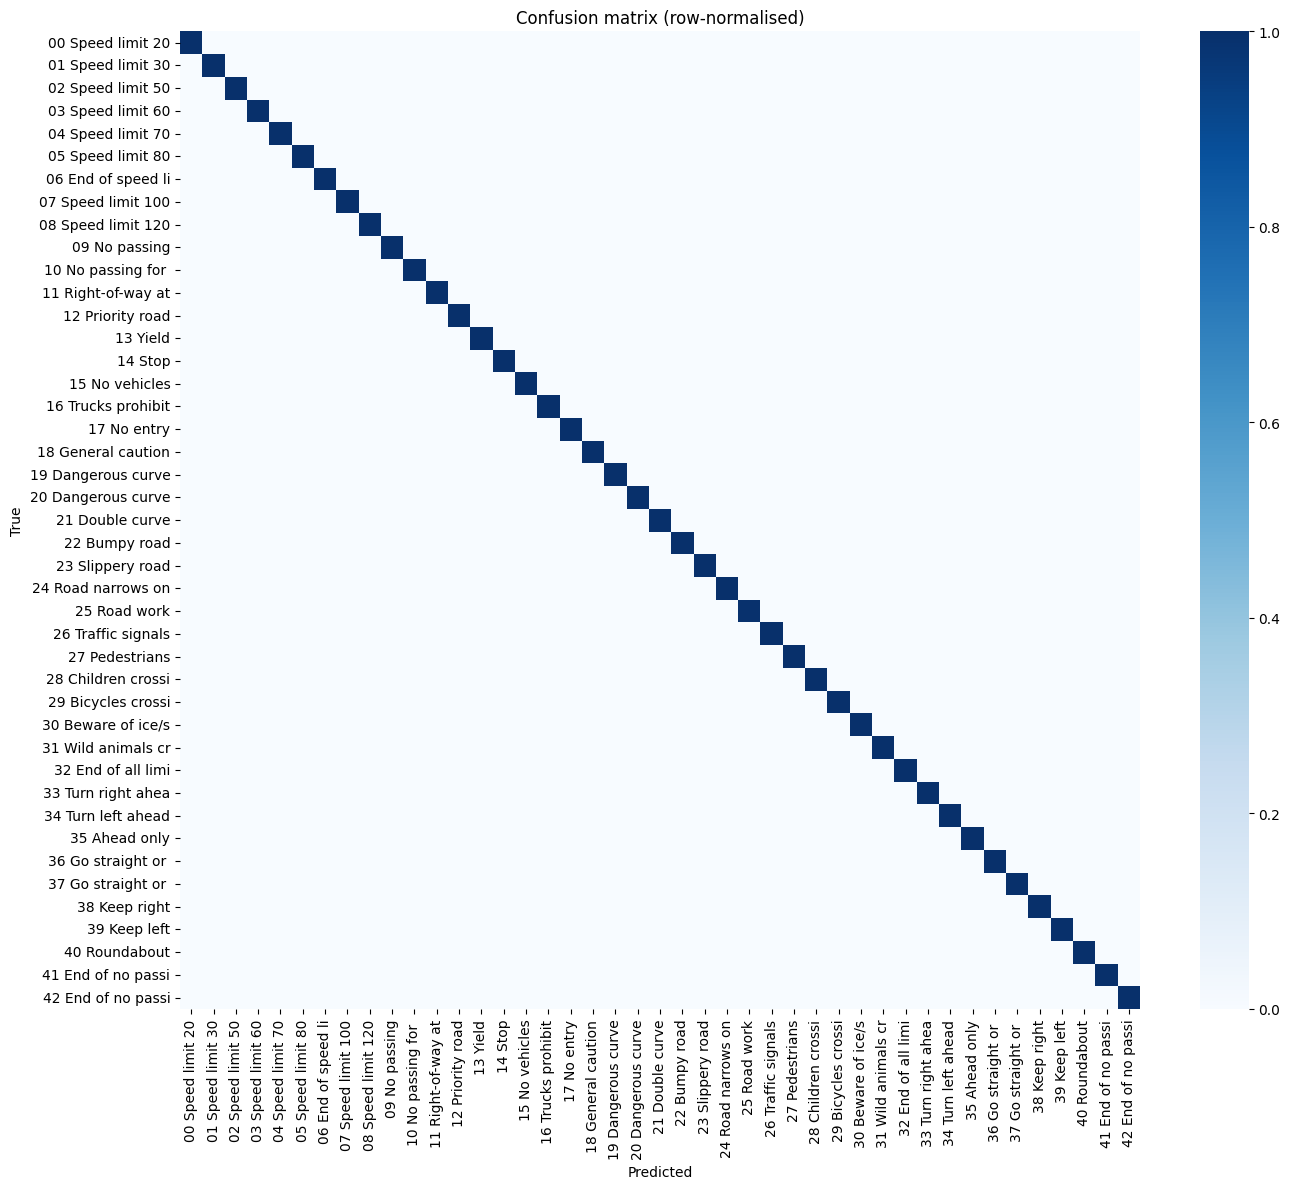

,True sign,Predicted as,Count
0,04 Speed limit 70,01 Speed limit 30,1
1,25 Road work,12 Priority road,1
2,25 Road work,11 Right-of-way at next intersection,1
3,03 Speed limit 60,05 Speed limit 80,1
4,05 Speed limit 80,02 Speed limit 50,1


In [ ]:
cm = confusion_matrix(y_test, test_pred)
cm_norm = cm / cm.sum(1, keepdims=True)
plt.figure(figsize=(14, 12))
short = [c[:18] for c in classes]
sns.heatmap(cm_norm, cmap="Blues", xticklabels=short, yticklabels=short, vmin=0, vmax=1)
plt.title("Confusion matrix (row-normalised)"); plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout(); plt.show()

# The most common mix-ups
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = [(classes[i], classes[j], off[i, j]) for i, j in zip(*np.unravel_index(np.argsort(off, axis=None)[::-1][:8], off.shape)) if off[i, j] > 0]
pd.DataFrame(pairs, columns=["True sign", "Predicted as", "Count"])

**What to look for:** Errors between visually similar signs can be difficult for an image classifier to resolve. For example, speed-limit signs may differ by only one digit, while warning signs can share similar shapes and symbols. These errors are particularly important to review when considering a safety-related application.


### 11.3 Reviewing misclassified images

I inspect a sample of incorrect predictions to understand what may have contributed to each error. The review considers factors such as blur, low brightness, cropping, partial visibility and similarity between sign designs.


Wrong predictions: 5 of 7775


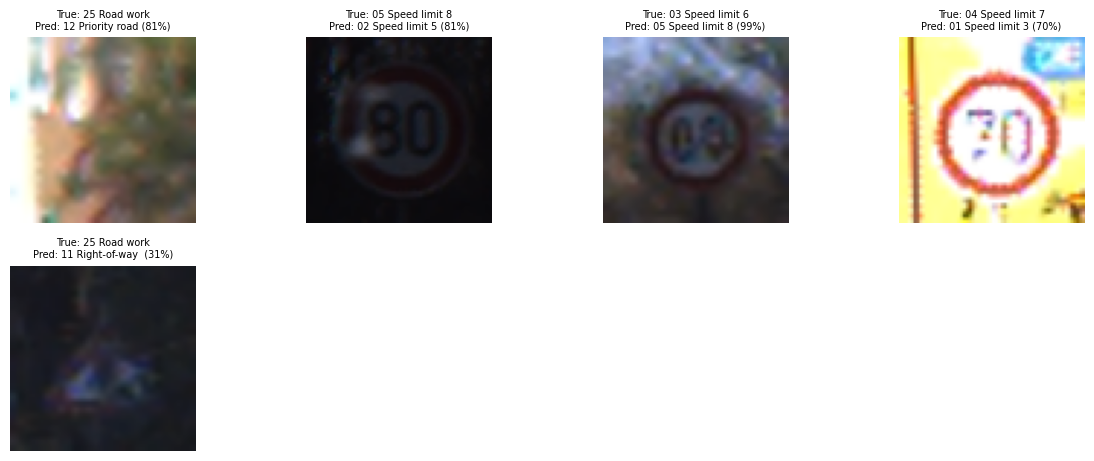

In [ ]:
wrong = np.where(test_pred != y_test)[0]
print(f"Wrong predictions: {len(wrong)} of {len(y_test)}")
plt.figure(figsize=(12, 7))
for k, i in enumerate(wrong[:12]):
    plt.subplot(3, 4, k + 1)
    plt.imshow(X_test[i])
    plt.title(f"True: {classes[y_test[i]][:16]}\nPred: {classes[test_pred[i]][:16]} ({test_probs[i].max():.0%})", fontsize=7)
    plt.axis("off")
plt.tight_layout(); plt.show()

## 12. Robustness testing under challenging image conditions

The standard test set measures performance on the available images, but images captured by a road-facing camera can be affected by motion blur, darkness, glare, sensor noise or partial obstruction.

To explore this, I apply different image conditions to copies of the test images and measure the change in macro F1. This provides a simple way to compare how sensitive the selected model is to each type of visual degradation.

These experiments are controlled simulations; they are useful for identifying weaknesses, but they do not replace testing with real driving-camera footage.


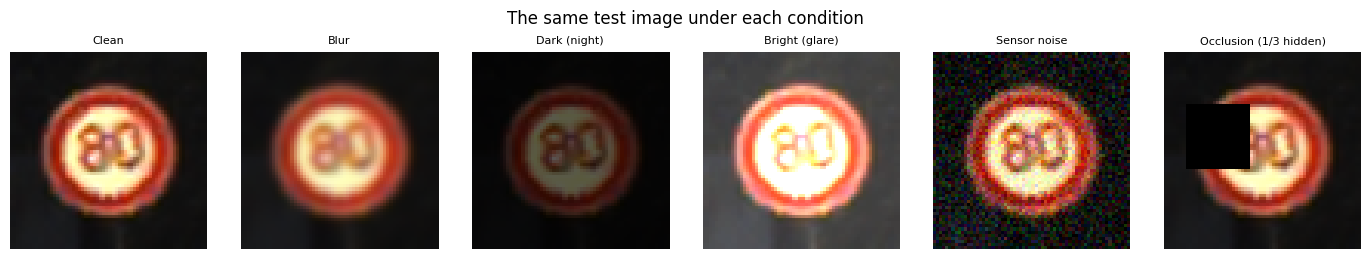

,Condition,Accuracy,Macro F1,Drop vs clean (F1 points)
0,Clean,0.9994,0.9997,0.0
1,Blur,0.9987,0.9988,0.1
2,Dark (night),0.9779,0.9821,1.8
3,Bright (glare),0.9576,0.9584,4.1
4,Sensor noise,0.7524,0.7782,22.2
5,Occlusion (1/3 hidden),0.8026,0.7892,21.0


In [ ]:
from scipy.ndimage import gaussian_filter
rng = np.random.default_rng(SEED)

def blur(X):   return np.stack([gaussian_filter(x.astype(float), sigma=(1.2, 1.2, 0)) for x in X]).clip(0, 255).astype("uint8")
def dark(X):   return (X * 0.35).astype("uint8")
def bright(X): return np.clip(X.astype(float) * 1.6 + 40, 0, 255).astype("uint8")
def noise(X):  return np.clip(X + rng.normal(0, 20, X.shape), 0, 255).astype("uint8")
def occlude(X):
    X = X.copy(); s = IMG_SIZE // 3
    for x in X:
        r, c = rng.integers(0, IMG_SIZE - s, 2); x[r:r + s, c:c + s] = 0
    return X

conditions = {"Clean": lambda X: X, "Blur": blur, "Dark (night)": dark, "Bright (glare)": bright,
              "Sensor noise": noise, "Occlusion (1/3 hidden)": occlude}
robust = []
examples = {}
for name, fn in conditions.items():
    Xc = fn(X_test)
    examples[name] = Xc[0]
    _, pred, acc, f1, _ = evaluate(best, Xc, y_test)
    robust.append({"Condition": name, "Accuracy": round(acc, 4), "Macro F1": round(f1, 4)})
robust = pd.DataFrame(robust)
robust["Drop vs clean (F1 points)"] = (robust["Macro F1"].iloc[0] - robust["Macro F1"]).mul(100).round(1)

fig, ax = plt.subplots(1, len(examples), figsize=(14, 2.6))
for a, (n, img) in zip(ax, examples.items()):
    a.imshow(img); a.set_title(n, fontsize=8); a.axis("off")
plt.suptitle("The same test image under each condition"); plt.tight_layout(); plt.show()
robust

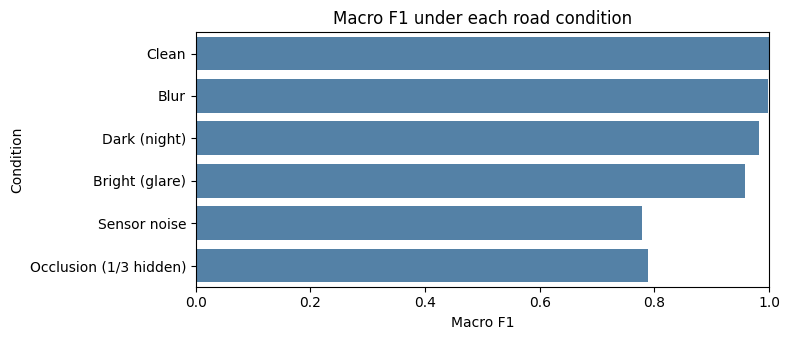

In [ ]:
plt.figure(figsize=(8, 3.5))
sns.barplot(data=robust, x="Macro F1", y="Condition", color="steelblue")
plt.xlim(0, 1); plt.title("Macro F1 under each road condition"); plt.tight_layout(); plt.show()

**How I interpret the results:** The largest drop in macro F1 points to a condition that deserves further investigation. A practical next step would be to include representative examples of that condition in training augmentation and collect more real images captured under similar circumstances. This gives the next improvement cycle a measurable starting point.


## 13. Confidence and uncertain predictions

In a driver-assistance setting, a confident but incorrect prediction can be more concerning than a prediction the system chooses not to use. One possible approach is to allow the model to abstain when its confidence is below a chosen threshold.

The model's highest predicted class probability is used as its confidence score. I examine:

1. Whether incorrect predictions tend to have lower confidence than correct predictions.
2. How the accuracy of accepted predictions changes as the confidence threshold increases.
3. How many predictions would be skipped at each threshold.

This analysis illustrates the trade-off between prediction coverage and reliability. A threshold from this experiment should not be treated as a production safety setting without further validation.


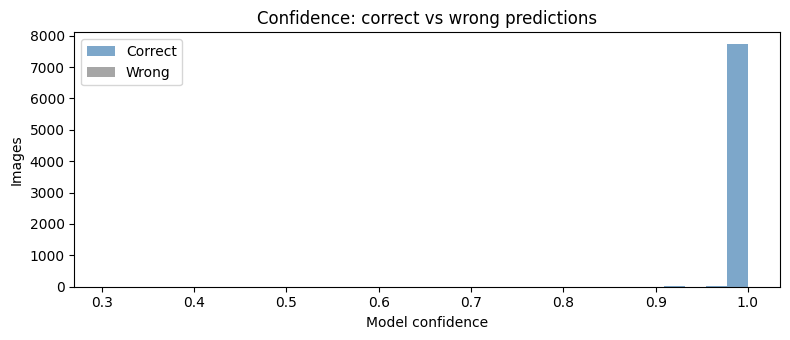

,Threshold,Frames accepted,Accuracy on accepted
0,0.00,100.0%,0.9994
1,0.50,99.9%,0.9995
2,0.70,99.9%,0.9995
3,0.80,99.8%,0.9996
4,0.90,99.6%,0.9999
5,0.95,99.4%,0.9999
6,0.99,99.1%,0.9999


In [ ]:
conf = test_probs.max(1)
correct = test_pred == y_test
plt.figure(figsize=(8, 3.5))
plt.hist(conf[correct], bins=30, alpha=0.7, label="Correct", color="steelblue")
plt.hist(conf[~correct], bins=30, alpha=0.7, label="Wrong", color="gray")
plt.xlabel("Model confidence"); plt.ylabel("Images"); plt.legend(); plt.title("Confidence: correct vs wrong predictions")
plt.tight_layout(); plt.show()

rows = []
for t in [0.0, 0.5, 0.7, 0.8, 0.9, 0.95, 0.99]:
    keep = conf >= t
    rows.append({"Threshold": t, "Frames accepted": f"{keep.mean():.1%}",
                 "Accuracy on accepted": round(correct[keep].mean(), 4) if keep.any() else None})
pd.DataFrame(rows)

**Interpretation:** If incorrect predictions tend to have lower confidence, a threshold may improve the accuracy of the predictions that are accepted, at the cost of skipping more images. In a real deployment, the threshold and the behaviour when a prediction is rejected would need to be validated with the relevant safety requirements.


## 14. Saving the model and predicting an image

I save the selected model so it can be loaded later without repeating the training process. I also define a prediction function that accepts an image and returns the top three predicted classes with their scores.

This provides a small, reusable inference step that can be connected to an application or API.


In [ ]:
import json
best.save("traffic_sign_model.keras")
with open("classes.json", "w") as f:
    json.dump({"classes": classes, "img_size": IMG_SIZE}, f, indent=1)
print("Saved traffic_sign_model.keras and classes.json (both are needed by the FastAPI app)")

def predict_sign(path, model=best, top_k=3):
    img = np.asarray(Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))[None]
    p = model.predict(img, verbose=0)[0]
    top = p.argsort()[::-1][:top_k]
    return [(classes[i], round(float(p[i]), 3)) for i in top]

example = df.sample(1, random_state=1).iloc[0]
print("True:", example["label"])
print("Predicted:", predict_sign(example["path"]))

Saved traffic_sign_model.keras and classes.json (both are needed by the FastAPI app)
True: 01 Speed limit 30
Predicted: [('01 Speed limit 30', 1.0), ('02 Speed limit 50', 0.0), ('04 Speed limit 70', 0.0)]


### Preparing model files for an application

The following cell downloads the saved model files so they can be placed in the `model/` directory of the FastAPI application. The notebook focuses on training and inference; the application can use these exported files without retraining the model.


In [ ]:
try:
    from google.colab import files
    files.download("traffic_sign_model.keras")
    files.download("classes.json")
except ImportError:
    print("Not running in Colab: the files are in the current folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. Challenges, learnings and conclusion

### Challenges addressed

1. **Mismatch in the project brief:** the business-case text referred to gender prediction, which did not match the title or the supplied data. I followed the traffic-sign recognition task supported by the dataset.
2. **Dataset folder structure:** I adapted the loader to find images across the available folder structure and handle the separate train and test folders.
3. **Duplicate and unreadable images:** I checked image files and used file hashes to identify exact duplicates, reducing the risk of the same image appearing in both training and evaluation data.
4. **Class imbalance:** I used class weights during training and macro F1 during evaluation so that performance on less frequent signs remained visible.
5. **Incorrect labels from the test folder:** test images are stored together and their labels are provided in `Test.csv`. Reading labels from the CSV and excluding the reference drawings corrected the initial loading issue.
6. **Training callbacks:** I created fresh callback objects for each model run so that training decisions for one model would not depend on another model's training history.
7. **Low-resolution images:** I used 64 × 64 images for the main pipeline and resized inputs to 96 × 96 inside MobileNetV2.
8. **Augmentation choices:** I excluded horizontal flips because they can change the meaning of directional traffic signs.
9. **Traditional model features:** I compared raw-pixel features with HOG edge features to understand how feature representation affects the baseline models.
10. **Evaluation beyond accuracy:** I added class-level error analysis, robustness checks and confidence-threshold analysis to investigate limitations that a single accuracy score would not show.

### Conclusion

This notebook compares four approaches to traffic-sign recognition: Random Forest on raw pixels, HOG + Linear SVM, a CNN trained from scratch and MobileNetV2 using transfer learning.

The evaluation covers validation and test performance, class-level errors, confusion between sign categories, robustness to simulated image conditions and the trade-off between confidence and prediction coverage. The results in the notebook should be used to understand the strengths and limitations observed in these experiments.

### Possible next steps

- Add training examples and suitable augmentation for the image condition that caused the largest performance drop.
- Collect more examples for the classes with the lowest F1 scores.
- Test the model on real road-camera footage to understand how it behaves outside this dataset.
- Combine classification with an object detector, such as YOLO, to locate traffic signs in full camera frames before classifying them.

This project gave me practical experience with image preprocessing, traditional machine learning, CNNs, transfer learning and model evaluation, while highlighting why robustness and uncertainty matter in applied computer vision.
